# AME 5152 — Applied Probability and Statistics
## Mid-Semester Examination — AIML Set 2

This notebook answers the questions in **QP MSE_AIML_Set2.docx** using simple Python code and comments.

**Required libraries:** `numpy`, `matplotlib`, `scikit-learn`, `pandas`, and `scipy`.

Install them if needed:
```python
%pip install numpy matplotlib scikit-learn pandas scipy
```


# Question 1 — Anomaly Detection

An anomaly detection model gives a score to each transaction. A transaction is predicted as anomalous when its score is at least the selected threshold. Class 1 means anomalous.

Complete the missing lines A–H. **Do not change the data-generation code.** Run the program and answer the questions.

1. At threshold 0.60, how many anomalies are detected and how many normal transactions are incorrectly flagged?
2. What do sensitivity, specificity, and precision mean at threshold 0.60?
3. What happens to TP, FP, sensitivity, and precision when the threshold changes from 0.60 to 0.35? Explain why.
4. What are ROC AUC and average precision? What does the dashed line at 0.08 represent on the precision–recall plot?
5. Which threshold would you choose if investigating a false alarm is expensive? Justify using the results.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

# Do not modify this data-generation code
rng = np.random.default_rng(42)

positive_scores = rng.beta(5, 2, size=80)
negative_scores = rng.beta(2, 5, size=920)

y_true = np.r_[np.ones(80, dtype=int), np.zeros(920, dtype=int)]
scores = np.r_[positive_scores, negative_scores]


def evaluate_threshold(threshold):
    # A. Predict class 1 when score is at least the threshold.
    y_pred = (scores >= threshold).astype(int)

    # B. confusion_matrix with labels [0, 1] returns TN, FP, FN, TP in this order.
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    # C–E. Calculate metrics safely.
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0

    print(f"\nThreshold = {threshold:.2f}")
    print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")
    print(f"Sensitivity = {sensitivity:.4f}")
    print(f"Specificity = {specificity:.4f}")
    print(f"Precision   = {precision:.4f}")

    return {
        "Threshold": threshold, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Sensitivity": sensitivity, "Specificity": specificity,
        "Precision": precision
    }


# Evaluate both thresholds
result_060 = evaluate_threshold(0.60)
result_035 = evaluate_threshold(0.35)



Threshold = 0.60
TN = 882, FP = 38, FN = 15, TP = 65
Sensitivity = 0.8125
Specificity = 0.9587
Precision   = 0.6311

Threshold = 0.35
TN = 618, FP = 302, FN = 3, TP = 77
Sensitivity = 0.9625
Specificity = 0.6717
Precision   = 0.2032



ROC AUC = 0.9586
Average precision = 0.7964
Anomaly prevalence = 0.0800


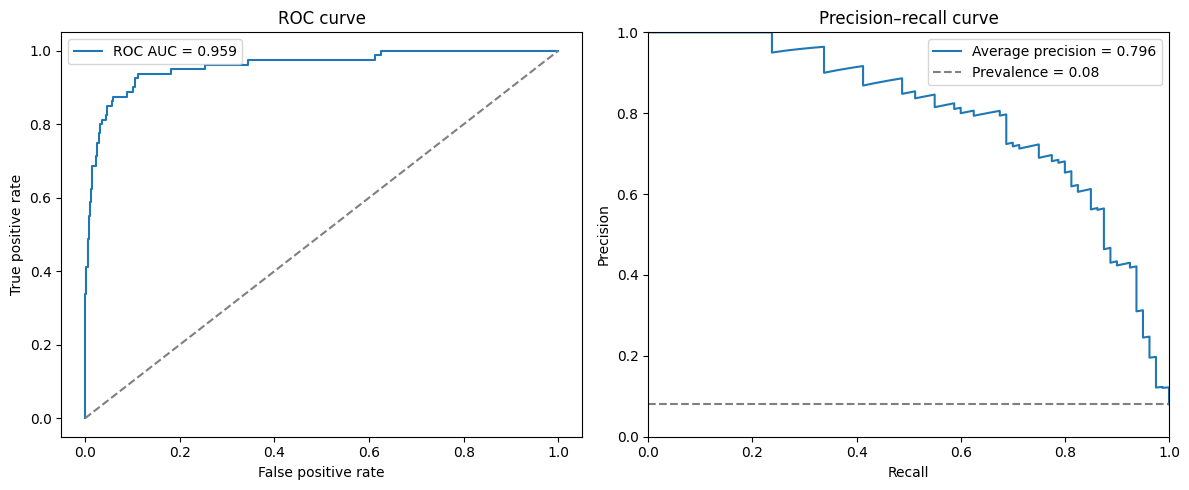

In [2]:
# F. Calculate the values needed for the ROC curve.
fpr, tpr, roc_thresholds = roc_curve(y_true, scores)

# G. Calculate the values needed for the precision–recall curve.
pr_precision, pr_recall, pr_thresholds = precision_recall_curve(y_true, scores)

# H. Calculate ROC AUC, average precision, and class prevalence.
roc_auc = roc_auc_score(y_true, scores)
avg_precision = average_precision_score(y_true, scores)
prevalence = np.mean(y_true)

print(f"\nROC AUC = {roc_auc:.4f}")
print(f"Average precision = {avg_precision:.4f}")
print(f"Anomaly prevalence = {prevalence:.4f}")

# Plot both curves.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(fpr, tpr, label=f"ROC AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(
    title="ROC curve",
    xlabel="False positive rate",
    ylabel="True positive rate"
)
axes[0].legend()

axes[1].plot(
    pr_recall, pr_precision,
    label=f"Average precision = {avg_precision:.3f}"
)
axes[1].axhline(
    prevalence,
    linestyle="--",
    color="gray",
    label=f"Prevalence = {prevalence:.2f}"
)
axes[1].set(
    title="Precision–recall curve",
    xlabel="Recall",
    ylabel="Precision",
    xlim=(0, 1),
    ylim=(0, 1)
)
axes[1].legend()

plt.tight_layout()
plt.show()


## Question 1 — Short Answers

- **TP (true positives):** anomalous transactions correctly detected.
- **FP (false positives):** normal transactions incorrectly flagged as anomalous.
- **Sensitivity (recall):** proportion of all actual anomalies detected, \(TP/(TP+FN)\).
- **Specificity:** proportion of normal transactions correctly left unflagged, \(TN/(TN+FP)\).
- **Precision:** proportion of flagged transactions that really are anomalous, \(TP/(TP+FP)\).
- **ROC AUC:** summarizes how well the score ranks anomalies above normal transactions across thresholds; 1 is perfect and about 0.5 is chance-level.
- **Average precision:** summarizes the precision–recall curve, giving a useful overall view when the positive class is uncommon.
- The dashed horizontal line at **0.08** is the anomaly prevalence: 80 of the 1,000 transactions are anomalous, so the baseline prevalence is 8%.

Lowering the threshold from 0.60 to 0.35 flags more transactions. TP usually increases, but FP can also increase. Sensitivity tends to increase because fewer anomalies are missed; precision may decrease because more normal transactions can be incorrectly flagged. Use the printed results to report the exact changes for this dataset.

If investigating a false alarm is expensive, prefer the threshold with fewer **FPs** (and typically higher specificity), while noting how many true anomalies are missed.


# Question 2 — Number of Failed Server Requests

A monitoring system checks 12 independent server requests during each minute. Each request has probability 0.20 of failing. Let \(X\) be the number of failed requests in one minute.

Write Python code to:
1. Identify the distribution of \(X\), its parameters, and possible values.
2. Simulate 20,000 minutes and calculate the empirical PMF for every possible value of \(X\).
3. Calculate and plot the theoretical PMF alongside the empirical PMF.
4. Calculate empirical and theoretical expectation and variance, and present the four values in a table.
5. Estimate a probability from simulation and calculate it theoretically.

**Note:** In the supplied Set 2 document, the last bullet does not specify which probability event to use. The example below uses \(P(X \geq 4)\). Change the event if your instructor intended a different one.


,Number of failures (X),Empirical PMF,Theoretical PMF
0,0,0.06855,0.06872
1,1,0.20795,0.20616
2,2,0.27965,0.28347
3,3,0.24005,0.23622
4,4,0.13085,0.13288
5,5,0.05315,0.05315
6,6,0.01515,0.01550
7,7,0.00395,0.00332
8,8,0.00060,0.00052
9,9,0.00010,0.00006


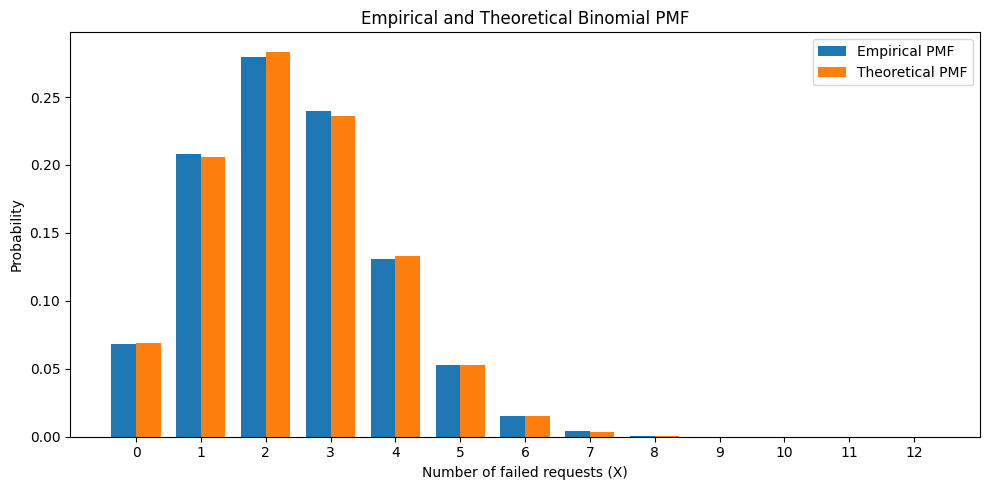

,Measure,Empirical,Theoretical
0,Expectation,2.40080,2.40
1,Variance,1.93096,1.92


Empirical P(X >= 4) = 0.20380
Theoretical P(X >= 4) = 0.20543


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binom

# X follows a Binomial distribution because there are 12 independent trials,
# each with the same probability (0.20) of failure.
n = 12
p = 0.20
num_minutes = 20_000

# Possible values are 0, 1, 2, ..., 12 failures.
values = np.arange(n + 1)

# Simulate the number of failures in each of 20,000 minutes.
rng = np.random.default_rng(42)
samples = rng.binomial(n=n, p=p, size=num_minutes)

# Empirical PMF: observed proportion of minutes with each possible value.
empirical_pmf = np.array([np.mean(samples == x) for x in values])

# Theoretical PMF from the Binomial distribution.
theoretical_pmf = binom.pmf(values, n, p)

# Display both PMFs in a table.
pmf_table = pd.DataFrame({
    "Number of failures (X)": values,
    "Empirical PMF": empirical_pmf,
    "Theoretical PMF": theoretical_pmf
})
display(pmf_table.round(5))

# Plot empirical and theoretical PMFs together.
width = 0.38
plt.figure(figsize=(10, 5))
plt.bar(values - width/2, empirical_pmf, width=width, label="Empirical PMF")
plt.bar(values + width/2, theoretical_pmf, width=width, label="Theoretical PMF")
plt.xlabel("Number of failed requests (X)")
plt.ylabel("Probability")
plt.title("Empirical and Theoretical Binomial PMF")
plt.xticks(values)
plt.legend()
plt.tight_layout()
plt.show()

# Calculate empirical and theoretical expectation and variance.
empirical_mean = np.mean(samples)
empirical_variance = np.var(samples)  # population variance, ddof=0
theoretical_mean = binom.mean(n, p)
theoretical_variance = binom.var(n, p)

summary_table = pd.DataFrame({
    "Measure": ["Expectation", "Variance"],
    "Empirical": [empirical_mean, empirical_variance],
    "Theoretical": [theoretical_mean, theoretical_variance]
})
display(summary_table.round(5))

# Example probability: P(X >= 4).
# Estimate from simulation and calculate it theoretically.
empirical_probability = np.mean(samples >= 4)
theoretical_probability = binom.sf(3, n, p)  # sf(3) = P(X > 3) = P(X >= 4)

print(f"Empirical P(X >= 4) = {empirical_probability:.5f}")
print(f"Theoretical P(X >= 4) = {theoretical_probability:.5f}")


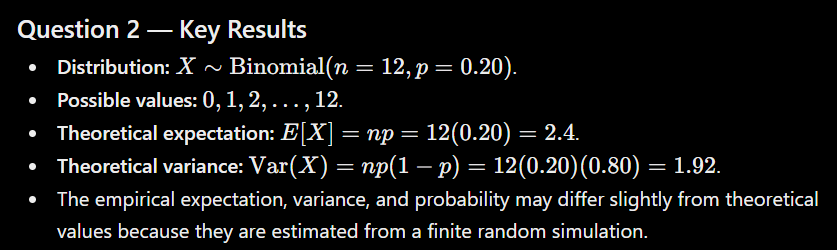